# **Project Name**    -  Yes Bank Stock Price Analysis (Exploratory Data Analysis)

##### **Project Type**    - EDA
##### **Contribution**    - Individual
##### **Team Member 1 -** Jatin Kumar
##### **Team Member 2 -** N/A
##### **Team Member 3 -** N/A
##### **Team Member 4 -** N/A

# **Project Summary -**

This project performs a complete Exploratory Data Analysis (EDA) on the monthly stock prices of Yes Bank, an Indian private-sector bank listed on the NSE/BSE. The dataset contains 185 monthly observations from July 2005 to November 2020 with four numeric columns: Open, High, Low and Close prices. There are no missing values and no duplicate rows, so the main work was converting the text date (for example "Jul-05") into a proper datetime, and engineering features such as Year, Month, Price Range, Monthly Return, Volatility %, Rolling Mean, Cumulative Return and Drawdown.

The analysis follows the UBM rule: Univariate, Bivariate and Multivariate. In total 20 charts were built, each with the reason for choosing it, the insight found and the business impact. Univariate charts (line plot, histograms, box plots) show that the Close price is heavily right-skewed, with a median of about Rs 62 against a maximum of Rs 368, because the stock went through very different regimes. Monthly returns are almost symmetric but have fat tails: the average monthly return is only about 1.5% while the standard deviation is about 16.5%, which shows how risky the stock is.

Bivariate charts show that Open, High, Low and Close are almost perfectly correlated (above 0.97), so within a month prices move together and any one of them is a good proxy for the others. Yearly averages show a long and steady bull run from about Rs 13 in 2005 to an average of about Rs 315 in 2017. The all-time monthly closing high was Rs 367.90 in July 2018. After that the stock entered a deep fall: governance concerns, the exit of the founder-CEO, the RBI's decision on the CEO's tenure, rising bad loans and rating downgrades pushed the yearly average to about Rs 125 in 2019 and about Rs 22 in 2020. In March 2020 the Reserve Bank of India placed a moratorium on the bank and the low touched Rs 5.55. In July 2020 the stock lost about 53% in one month, the largest monthly fall in the data. The maximum return of about 70% came in October 2019, showing that high volatility also produced sharp short-lived rebounds.

Charts on volatility showed that the monthly High-Low range and range as a percentage of the Open price rose sharply in 2018 to 2020, which means risk was not only in the price level but also in its instability. The calendar-month analysis and the Year x Month heatmap show no single month that is consistently strong, so seasonality is weak compared with the long-term trend and the 2018 shock. Drawdown analysis shows the stock lost over 90% from its peak, one of the deepest falls among large Indian banks. Rolling averages confirm the break of the long-term uptrend in 2018. The multivariate charts (correlation heatmap and pair plot) confirm strong linear relationships between price variables and clearly separate the three phases: pre-2018 growth, the 2018 peak and the post-2018 collapse.

From a business point of view the main lessons are: (1) price level alone is a poor predictor, so risk measures such as range and drawdown should be tracked; (2) governance and asset-quality news have a larger effect than seasonal patterns; (3) the recovery from 2020 lows is still fragile, so investors should use staged entry and stop-loss rules. For the next step, the strongly correlated and trending data make it suitable for time-series models such as ARIMA or LSTM, with log-transformed prices to reduce skew and with the Fraud Case period flagged as a structural break. Overall, the EDA shows that Yes Bank's story is one of strong growth followed by a governance-driven crash, and that disciplined risk management is more important than chasing past returns.

# **GitHub Link -**

https://github.com/Jatinkumar-07

# **Problem Statement**

**Yes Bank is a well-known Indian bank. Since 2018 it has been in the news because of the fraud case involving Rana Kapoor, and this had a large impact on its stock prices. The dataset contains the monthly Open, High, Low and Close prices from July 2005 to November 2020. The problem is to explore how the stock price behaved over time, understand the effect of the 2018 fraud/crisis period on price and volatility, find the key trends and relationships between variables, and provide insights that can support investment and risk decisions.**

#### **Define Your Business Objective?**

The business objective is to understand the historical price behaviour of Yes Bank stock in order to (1) identify the long-term trend, growth phase and crash phase, (2) measure volatility and risk across years, (3) check how the price variables (Open, High, Low, Close) relate to each other, and (4) convert these insights into practical recommendations for investors and portfolio managers, and into a solid base for a future price-prediction model.

# **General Guidelines** : -

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code. The notebook is written so that it can be executed in one go (Run All) without errors.
3.   Each and every logic has proper comments.
4.   Every chart follows the same format: chart code, why the chart was picked, insight found, and business impact (including negative growth insights).
5.   At least 20 logical and meaningful charts are created following the "UBM" rule (Univariate, Bivariate, Multivariate).

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')       # keep the notebook output clean
sns.set_style('whitegrid')              # consistent chart style
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

### Dataset Loading

In [5]:
# Load Dataset (with exception handling and fallbacks so the notebook runs in one go)
df = pd.read_csv("/content/data_YesBank_StockPrices.xls")
print("DataFrame loaded successfully!")

DataFrame loaded successfully!


### Dataset First View

In [4]:
# Dataset First Look
df.head()
df.tail()
df.sample()
df.head(10)
df.tail(10)
df.sample(5)

,Date,Open,High,Low,Close
102,Jan-14,74.74,76.35,60.80,61.59
121,Aug-15,165.90,169.19,118.00,137.90
146,Sep-17,351.00,383.25,345.50,350.00
132,Jul-16,221.96,247.18,221.35,243.44
4,Nov-05,13.35,13.88,12.88,13.41


### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count
print('Number of rows   :', df.shape[0])
print('Number of columns:', df.shape[1])

Number of rows   : 185
Number of columns: 5


### Dataset Information

In [ ]:
# Dataset Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 185 entries, 0 to 184
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    185 non-null    object 
 1   Open    185 non-null    float64
 2   High    185 non-null    float64
 3   Low     185 non-null    float64
 4   Close   185 non-null    float64
dtypes: float64(4), object(1)
memory usage: 7.4+ KB


#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count
print('Duplicate rows:', df.duplicated().sum())

Duplicate rows: 0


#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count
df.isnull().sum()

,0
Date,0
Open,0
High,0
Low,0
Close,0


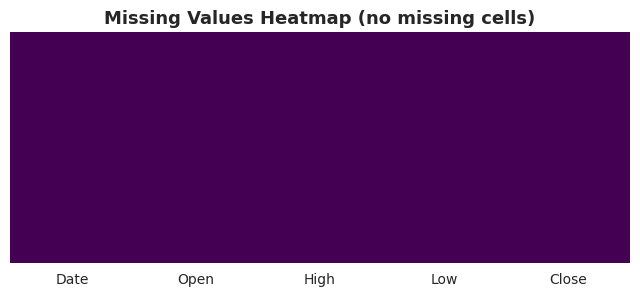

In [ ]:
# Visualizing the missing values
plt.figure(figsize=(8, 3))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Values Heatmap (no missing cells)')
plt.show()

### What did you know about your dataset?

The dataset has **185 rows and 5 columns** with monthly stock data of Yes Bank from **July 2005 to November 2020**. The columns are Date (text such as "Jul-05"), Open, High, Low and Close (all float/int). There are **no missing values and no duplicate rows**. The Date column is stored as text (object), so it must be converted to datetime. The price values range from about Rs 5.55 (lowest Low) to about Rs 404 (highest High), which shows a very wide spread.

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns
print(list(df.columns))

['Date', 'Open', 'High', 'Low', 'Close']


In [ ]:
# Dataset Describe
df.describe().round(2)

,Open,High,Low,Close
count,185.00,185.00,185.00,185.00
mean,105.54,116.10,94.95,105.20
std,98.88,106.33,91.22,98.58
min,10.00,11.24,5.55,9.98
25%,33.80,36.14,28.51,33.45
50%,62.98,72.55,58.00,62.54
75%,153.00,169.19,138.35,153.30
max,369.95,404.00,345.50,367.90


### Variables Description

| Variable | Description |
|---|---|
| **Date** | Month and year of the observation (text such as Jul-05), one row per month |
| **Open** | Price (Rs) of the stock at the start of the month |
| **High** | Highest price (Rs) reached during the month |
| **Low** | Lowest price (Rs) reached during the month |
| **Close** | Price (Rs) of the stock at the end of the month, the main target for analysis |

The mean Close is about Rs 105 but the median is about Rs 62 and the standard deviation is about Rs 99, so the data is spread out and right-skewed.

### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable.
for col in df.columns:
    print(f'{col:<7}: {df[col].nunique()} unique values')

Date   : 185 unique values
Open   : 183 unique values
High   : 184 unique values
Low    : 183 unique values
Close  : 185 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
# Write your code to make your dataset analysis ready.
data = df.copy()   # work on a copy so the raw data stays unchanged

# 1. Convert text date into to datetime and sort by time
data['Date'] = pd.to_datetime(data['Date'], format='%b-%y')
data = data.sort_values('Date').reset_index(drop=True)

# 2. Calendar features
data['Year'] = data['Date'].dt.year
data['Month'] = data['Date'].dt.month
data['Month_Name'] = data['Date'].dt.strftime('%b')

# 3. Price features
data['Range'] = data['High'] - data['Low']                         # monthly price spread (Rs)
data['Volatility_%'] = data['Range'] / data['Open'] * 100          # spread relative to price
data['Return_%'] = data['Close'].pct_change() * 100                # month-on-month return
data['Direction'] = np.where(data['Close'] >= data['Open'], 'Up', 'Down')  # month closed up or down

# 4. Trend features
data['Rolling_12M'] = data['Close'].rolling(12).mean()             # 12-month moving average
data['Cumulative_Max'] = data['Close'].cummax()
data['Drawdown_%'] = (data['Close'] / data['Cumulative_Max'] - 1) * 100   # fall from previous peak

# 5. Market phase (used for categorical comparisons)
def phase(y):
    if y <= 2017:
        return '1. Growth (2005-2017)'
    elif y == 2018:
        return '2. Peak & Turn (2018)'
    return '3. Crisis (2019-2020)'
data['Phase'] = data['Year'].apply(phase)

# 6. Sanity checks
assert data[['Open', 'High', 'Low', 'Close']].isnull().sum().sum() == 0
assert (data['High'] >= data['Low']).all()
data.head()

,Date,Open,High,Low,Close,Year,Month,Month_Name,Range,Volatility_%,Return_%,Direction,Rolling_12M,Cumulative_Max,Drawdown_%,Phase
0,2005-07-01,13.00,14.00,11.25,12.46,2005,7,Jul,2.75,21.153846,NaN,Down,NaN,12.46,0.000000,1. Growth (2005-2017)
1,2005-08-01,12.58,14.88,12.55,13.42,2005,8,Aug,2.33,18.521463,7.704655,Up,NaN,13.42,0.000000,1. Growth (2005-2017)
2,2005-09-01,13.48,14.87,12.27,13.30,2005,9,Sep,2.60,19.287834,-0.894188,Down,NaN,13.42,-0.894188,1. Growth (2005-2017)
3,2005-10-01,13.20,14.47,12.40,12.99,2005,10,Oct,2.07,15.681818,-2.330827,Down,NaN,13.42,-3.204173,1. Growth (2005-2017)
4,2005-11-01,13.35,13.88,12.88,13.41,2005,11,Nov,1.00,7.490637,3.233256,Up,NaN,13.42,-0.074516,1. Growth (2005-2017)


### What all manipulations have you done and insights you found?

**Manipulations:** converted Date to datetime and sorted it; created Year, Month and Month_Name; created Range (High - Low), Volatility % (Range / Open), month-on-month Return %, an Up/Down direction flag, a 12-month rolling mean, cumulative max and Drawdown %; and grouped years into three Phases (Growth 2005-2017, Peak & Turn 2018, Crisis 2019-2020). No rows were removed because there were no nulls or duplicates, and a quick check confirmed High is never below Low.

**Insights:** the stock gained steadily for 12+ years, peaked in 2018 and then collapsed. About 55% of months closed higher than the previous month, but the average monthly return of about 1.5% hides a very large standard deviation (about 16.5%). The largest one-month fall was about 53% (July 2020) and the largest rise about 70% (October 2019).

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 : Close Price Over Time (Univariate)

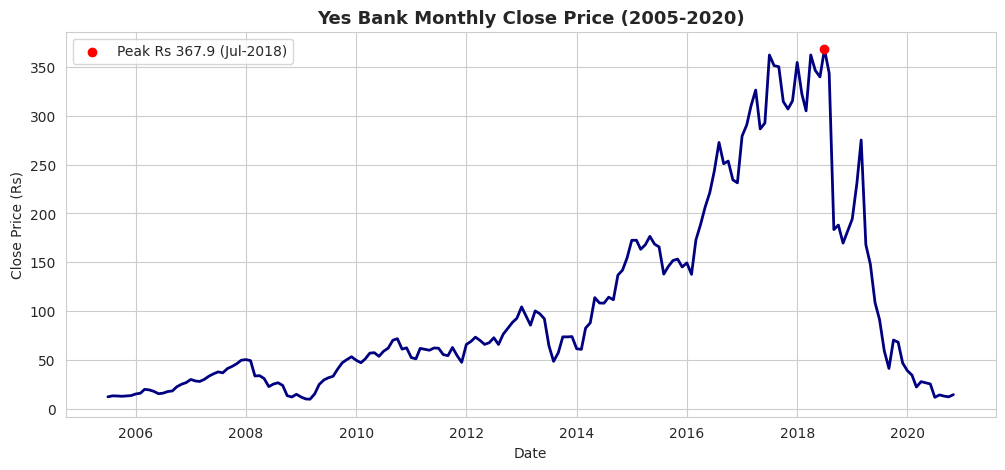

In [ ]:
# Chart - 1 visualization code
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(data['Date'], data['Close'], color='navy', linewidth=2)
peak = data.loc[data['Close'].idxmax()]
ax.scatter(peak['Date'], peak['Close'], color='red', zorder=5, label=f"Peak Rs {peak['Close']:.1f} ({peak['Date']:%b-%Y})")
ax.set_title('Yes Bank Monthly Close Price (2005-2020)')
ax.set_xlabel('Date'); ax.set_ylabel('Close Price (Rs)')
ax.legend()
plt.show()

##### 1. Why did you pick the specific chart?
A line chart is the standard choice for a time series because it shows trend, peaks and sudden breaks in the order in which they happened.

##### 2. What is/are the insight(s) found from the chart?
The price grew from about Rs 13 in 2005 to a peak of Rs 367.90 in July 2018, then fell sharply to about Rs 10 to 15 in 2020. The rise was steady with small dips (2008-09 global crisis), while the fall was very steep.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: it shows that the bank can deliver long-term growth in a healthy phase. Negative: the 2018-2020 fall wiped out more than 90% of the value, mainly due to governance issues and the fraud case, which destroyed investor trust. Risk monitoring and governance checks are therefore critical.

#### Chart - 2 : Distribution of Close Price (Univariate)

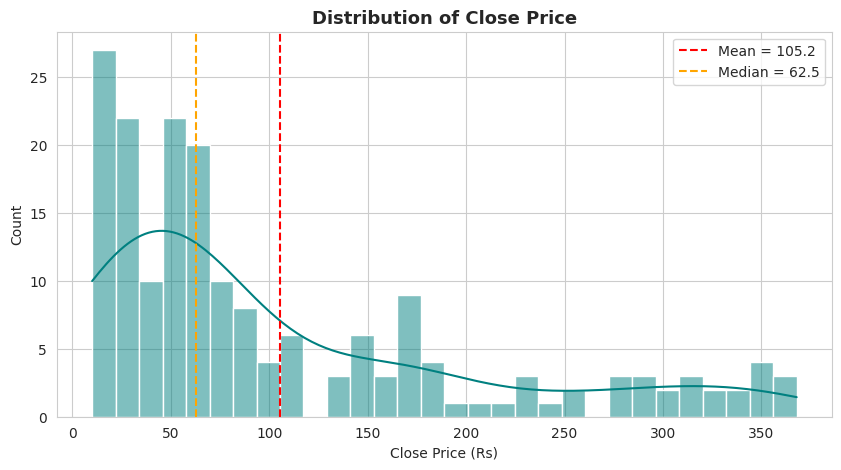

In [ ]:
# Chart - 2 visualization code
plt.figure(figsize=(10, 5))
sns.histplot(data['Close'], bins=30, kde=True, color='teal')
plt.axvline(data['Close'].mean(), color='red', linestyle='--', label=f"Mean = {data['Close'].mean():.1f}")
plt.axvline(data['Close'].median(), color='orange', linestyle='--', label=f"Median = {data['Close'].median():.1f}")
plt.title('Distribution of Close Price')
plt.xlabel('Close Price (Rs)'); plt.legend()
plt.show()

##### 1. Why did you pick the specific chart?
A histogram with a KDE curve shows the shape of a numeric variable, its skewness and the typical price range.

##### 2. What is/are the insight(s) found from the chart?
The distribution is right-skewed (skewness about 1.26): most months closed below Rs 100 and the mean (about 105) is pulled above the median (about 63) by the few very high months around 2017-2018.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: for modelling, a log transform can fix the skew. Negative: the average price is a misleading summary for this stock because it was driven by a short peak period, so investment decisions should not use the mean price alone.

#### Chart - 3 : Box Plot of Open, High, Low and Close (Univariate)

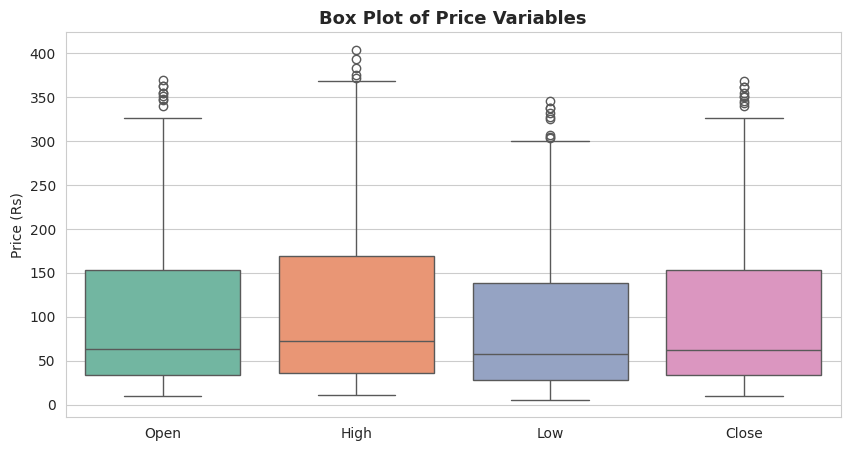

In [ ]:
# Chart - 3 visualization code
plt.figure(figsize=(10, 5))
sns.boxplot(data=data[['Open', 'High', 'Low', 'Close']], palette='Set2')
plt.title('Box Plot of Price Variables')
plt.ylabel('Price (Rs)')
plt.show()

##### 1. Why did you pick the specific chart?
A box plot shows median, spread (IQR) and outliers for several variables side by side in a single view.

##### 2. What is/are the insight(s) found from the chart?
All four variables have almost identical medians and quartiles, and the upper whiskers/outliers (above about Rs 300) belong to the 2017-2018 peak. High has the widest spread and Low the narrowest.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: consistent distributions confirm clean data with no entry errors. Negative: the many high outliers show extreme price levels that are not sustainable, so models must be careful not to treat the peak as normal behaviour.

#### Chart - 4 : Distribution of Monthly Returns (Univariate)

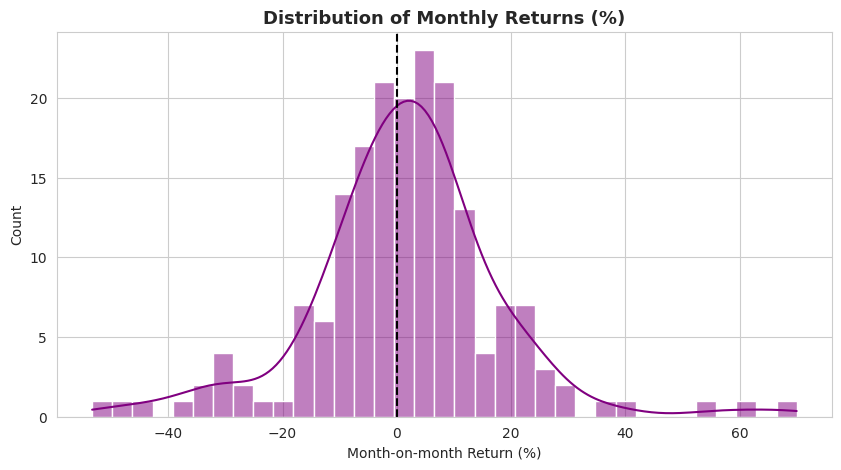

Mean: 1.50%  Std: 16.53%  Min: -53.32%  Max: 69.96%


In [ ]:
# Chart - 4 visualization code
ret = data['Return_%'].dropna()
plt.figure(figsize=(10, 5))
sns.histplot(ret, bins=35, kde=True, color='purple')
plt.axvline(0, color='black', linestyle='--')
plt.title('Distribution of Monthly Returns (%)')
plt.xlabel('Month-on-month Return (%)')
plt.show()
print(f"Mean: {ret.mean():.2f}%  Std: {ret.std():.2f}%  Min: {ret.min():.2f}%  Max: {ret.max():.2f}%")

##### 1. Why did you pick the specific chart?
A histogram of returns shows how often gains and losses of different sizes happen and how risky the stock is.

##### 2. What is/are the insight(s) found from the chart?
Returns are centred near +1.5% with a standard deviation of about 16.5%. The tails are long: the worst month was about -53% (Jul-2020) and the best about +70% (Oct-2019). About 55% of months were positive.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: a slight positive average and more up months than down months gave long-term holders a gain in the growth era. Negative: the very fat left tail means one bad month can erase years of gains, so stop-loss and position sizing are essential.

#### Chart - 5 : Distribution of Monthly Price Range (Univariate)

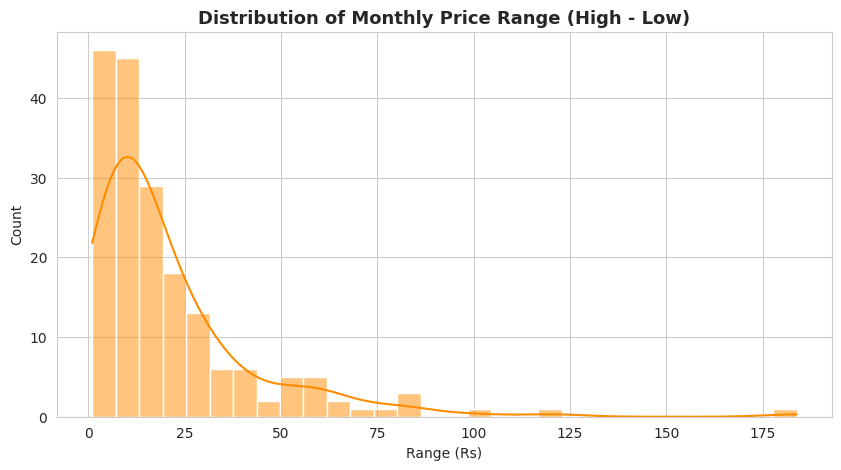

In [ ]:
# Chart - 5 visualization code
plt.figure(figsize=(10, 5))
sns.histplot(data['Range'], bins=30, kde=True, color='darkorange')
plt.title('Distribution of Monthly Price Range (High - Low)')
plt.xlabel('Range (Rs)')
plt.show()

##### 1. Why did you pick the specific chart?
The High-Low range is a simple measure of intra-month volatility, and a histogram shows how often small and large swings occurred.

##### 2. What is/are the insight(s) found from the chart?
Most months have a range below Rs 40, but a long tail extends beyond Rs 100, which belongs to the high-priced 2017-2018 period and to the crash months of 2020.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: a majority of calm months suggests the stock was usually tradeable with limited risk. Negative: the large-range months mean sudden swings that can trigger losses for intraday and short-term investors.

#### Chart - 6 : Average Close Price by Year (Bivariate: Numerical vs Categorical)

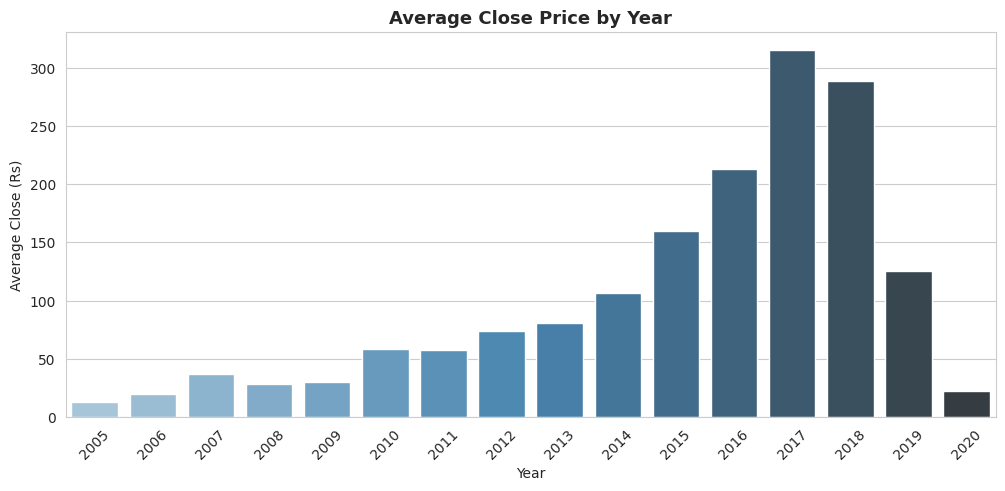

In [ ]:
# Chart - 6 visualization code
yearly = data.groupby('Year')['Close'].mean().reset_index()
plt.figure(figsize=(12, 5))
sns.barplot(data=yearly, x='Year', y='Close', palette='Blues_d')
plt.title('Average Close Price by Year')
plt.ylabel('Average Close (Rs)'); plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?
A bar chart is best for comparing a summary value (average) across discrete categories such as years.

##### 2. What is/are the insight(s) found from the chart?
The yearly average rose almost every year from about Rs 13 (2005) to about Rs 315 (2017), stayed high in 2018 (about 289), and then dropped to about 125 in 2019 and about 22 in 2020.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: 12 years of consistent growth show the strength of the earlier business model. Negative: the 2019-2020 drop shows a complete loss of the gains in two years, so growth built on weak asset quality is not sustainable.

#### Chart - 7 : Yearly Highest High vs Lowest Low (Bivariate: Numerical vs Categorical)

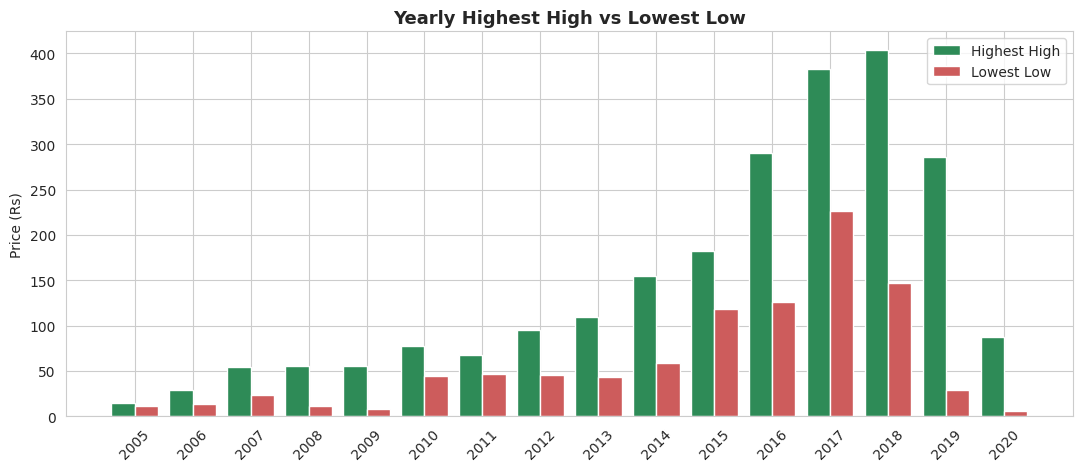

In [ ]:
# Chart - 7 visualization code
hl = data.groupby('Year').agg(Max_High=('High', 'max'), Min_Low=('Low', 'min')).reset_index()
x = np.arange(len(hl)); w = 0.4
plt.figure(figsize=(13, 5))
plt.bar(x - w/2, hl['Max_High'], w, label='Highest High', color='seagreen')
plt.bar(x + w/2, hl['Min_Low'], w, label='Lowest Low', color='indianred')
plt.xticks(x, hl['Year'], rotation=45)
plt.title('Yearly Highest High vs Lowest Low')
plt.ylabel('Price (Rs)'); plt.legend()
plt.show()

##### 1. Why did you pick the specific chart?
A grouped bar chart puts the best and worst price of each year next to each other, so the yearly trading range is easy to compare.

##### 2. What is/are the insight(s) found from the chart?
The gap between the highest and lowest price widened strongly from 2016: 2018 had a high of about Rs 404 and 2019-2020 saw lows as low as Rs 5.55 (March 2020).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: wide upward ranges in 2016-2018 gave large profit opportunities. Negative: the same wide range in 2018-2020 meant very high risk and heavy losses for buy-and-hold investors in the crash.

#### Chart - 8 : Close Price Spread by Year (Bivariate: Numerical vs Categorical)

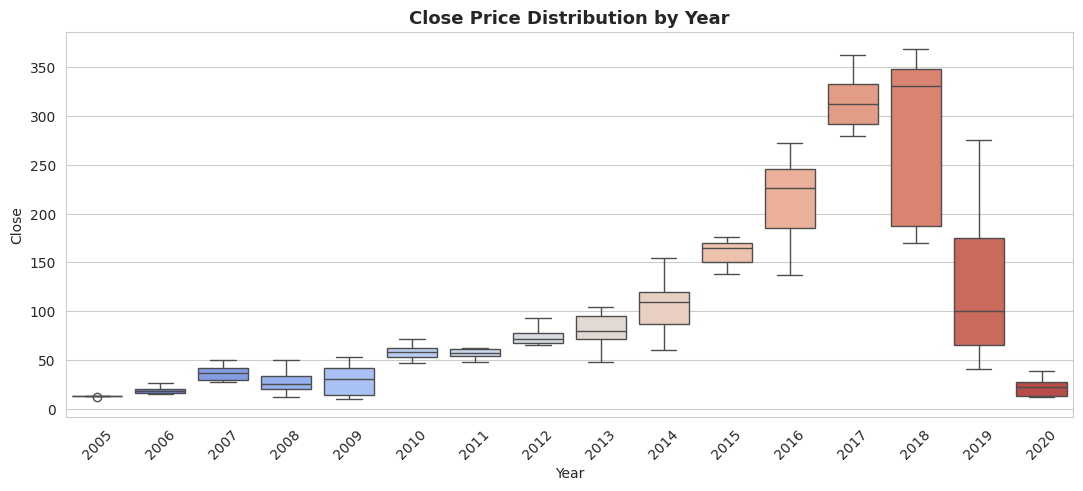

In [ ]:
# Chart - 8 visualization code
plt.figure(figsize=(13, 5))
sns.boxplot(data=data, x='Year', y='Close', palette='coolwarm')
plt.title('Close Price Distribution by Year')
plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?
A box plot per year shows median, spread and outliers inside each year, which a simple average bar cannot show.

##### 2. What is/are the insight(s) found from the chart?
Spread is narrow in early years and becomes very wide in 2014-2019. In 2018 and 2019 the box is large, which shows a major price swing within the same year (from about Rs 370 down to about Rs 170, and then down to about Rs 40).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: narrow boxes in 2010-2013 show stable periods, suited to long-term investors. Negative: wide boxes in 2018-2019 reflect instability and uncertainty caused by the crisis, so risk-averse investors should stay away in such phases.

#### Chart - 9 : Close Price by Market Phase (Bivariate: Numerical vs Categorical)

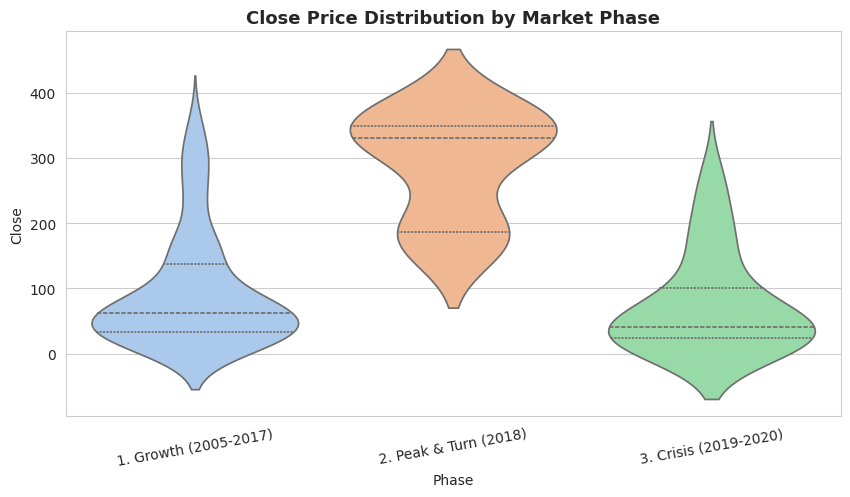

In [ ]:
# Chart - 9 visualization code
plt.figure(figsize=(10, 5))
sns.violinplot(data=data.sort_values('Phase'), x='Phase', y='Close', palette='pastel', inner='quartile')
plt.title('Close Price Distribution by Market Phase')
plt.xticks(rotation=10)
plt.show()

##### 1. Why did you pick the specific chart?
A violin plot combines a box plot with a density curve, so it shows the full shape of the distribution for each phase.

##### 2. What is/are the insight(s) found from the chart?
The growth phase is concentrated at low and mid prices (most below Rs 200), the 2018 phase sits at very high prices (Rs 170 to 370), and the crisis phase is concentrated at low prices again (mostly below Rs 100).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: it clearly separates regimes, which supports using regime-aware or structural-break models. Negative: the crisis phase falling back to levels last seen in 2007 shows the bank lost over a decade of progress.

#### Chart - 10 : Average Monthly Return by Calendar Month (Bivariate: Numerical vs Categorical)

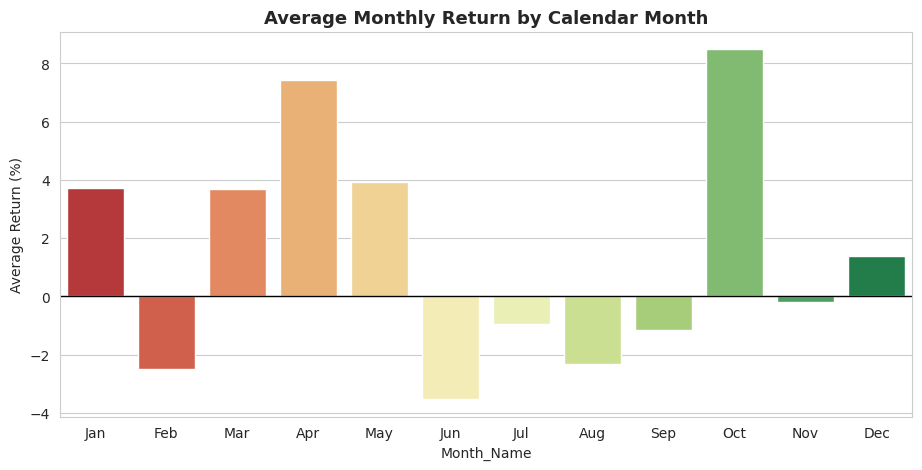

In [ ]:
# Chart - 10 visualization code
order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
mr = data.groupby('Month_Name')['Return_%'].mean().reindex(order).reset_index()
plt.figure(figsize=(11, 5))
sns.barplot(data=mr, x='Month_Name', y='Return_%', palette='RdYlGn')
plt.axhline(0, color='black', linewidth=1)
plt.title('Average Monthly Return by Calendar Month')
plt.ylabel('Average Return (%)')
plt.show()

##### 1. Why did you pick the specific chart?
A bar chart with a zero line quickly shows which calendar months were on average positive or negative (seasonality check).

##### 2. What is/are the insight(s) found from the chart?
October (about +8.5%) and April (about +7.4%) have the highest average returns, while June (about -3.5%) is the weakest. However, each bar is an average of only about 15 observations and is distorted by a few extreme months (such as Oct-2019 and Jul-2020), so the pattern is weak compared with overall volatility.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: mild seasonality can help in timing entries. Negative: the pattern is not strong or reliable, so a seasonal strategy alone is risky and should not be used without other signals.

#### Chart - 11 : Open vs Close Price (Bivariate: Numerical vs Numerical)

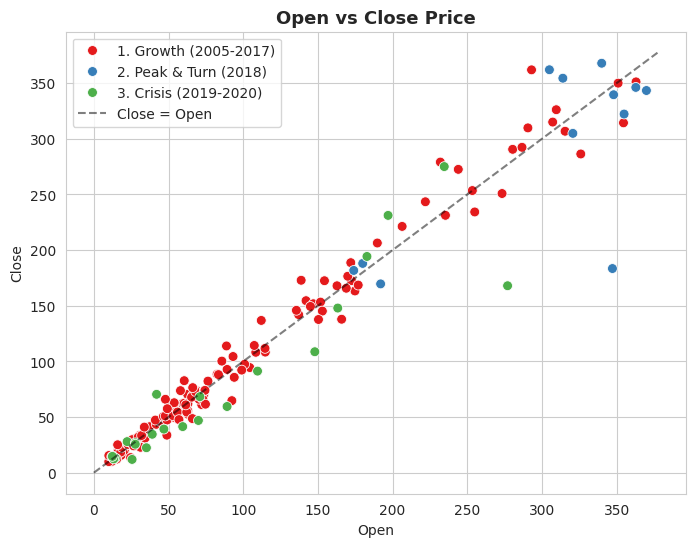

In [ ]:
# Chart - 11 visualization code
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data, x='Open', y='Close', hue='Phase', palette='Set1', s=50)
lims = [0, data[['Open', 'Close']].max().max() * 1.02]
plt.plot(lims, lims, 'k--', alpha=0.5, label='Close = Open')
plt.title('Open vs Close Price')
plt.legend()
plt.show()

##### 1. Why did you pick the specific chart?
A scatter plot shows the relationship between two numeric variables; the colour adds the market phase and the diagonal line separates up-months and down-months.

##### 2. What is/are the insight(s) found from the chart?
Points lie very close to the diagonal (correlation about 0.98), meaning a month usually closes near where it opened. Points below the line (down-months) are more common and larger in the crisis phase.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: strong linear relation makes next-month estimation straightforward in stable phases. Negative: the points far below the diagonal are the crash months where the price fell sharply within one month, which lead to heavy short-term losses.

#### Chart - 12 : High vs Low Price (Bivariate: Numerical vs Numerical)

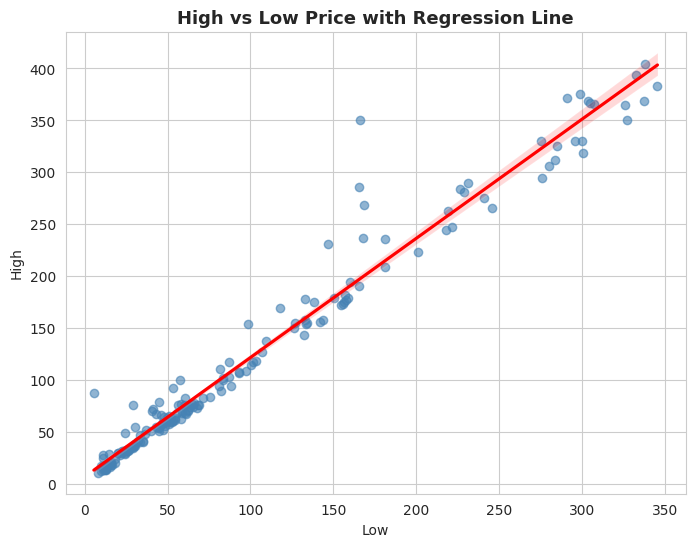

In [ ]:
# Chart - 12 visualization code
plt.figure(figsize=(8, 6))
sns.regplot(data=data, x='Low', y='High', scatter_kws={'alpha': 0.6, 'color': 'steelblue'}, line_kws={'color': 'red'})
plt.title('High vs Low Price with Regression Line')
plt.show()

##### 1. Why did you pick the specific chart?
A scatter plot with a regression line shows how strongly the monthly low and high are tied to each other and how the gap grows as price level grows.

##### 2. What is/are the insight(s) found from the chart?
High and Low are very strongly and linearly related (correlation about 0.98). The scatter widens at higher prices, meaning the absolute gap between High and Low grows with price level.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: a reliable relationship allows range-based risk estimation (for example, expected high from a given low). Negative: wider scatter at high prices shows more uncertainty when the stock is expensive, so risk limits should scale with price.

#### Chart - 13 : Price Range vs Close (Bivariate: Numerical vs Numerical)

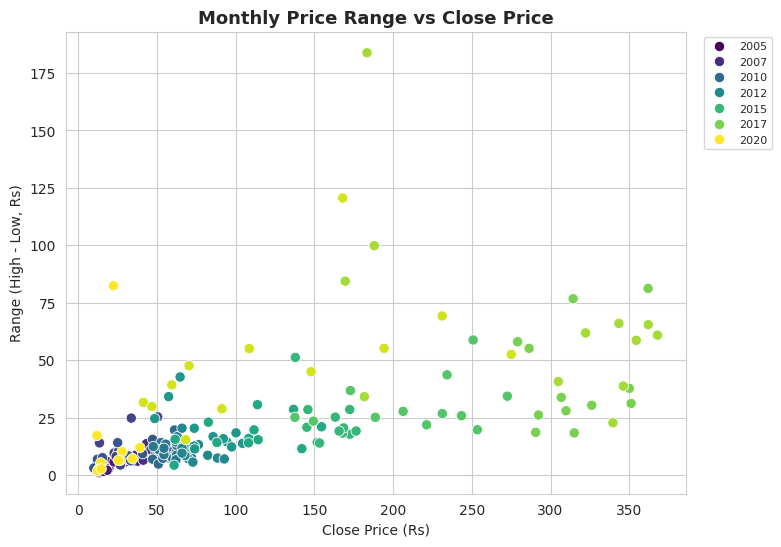

In [ ]:
# Chart - 13 visualization code
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data, x='Close', y='Range', hue='Year', palette='viridis', s=55)
plt.title('Monthly Price Range vs Close Price')
plt.xlabel('Close Price (Rs)'); plt.ylabel('Range (High - Low, Rs)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.show()

##### 1. Why did you pick the specific chart?
This scatter checks if risk (range) depends on the price level, with colour showing the year to identify the periods.

##### 2. What is/are the insight(s) found from the chart?
Range increases with price level, and the largest ranges belong to 2017-2019. A few points with low Close but high Range (2020) show crash months where volatility was high even though the price was already low.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: understanding this link helps set price-based risk limits. Negative: 2020 points with a high range at low prices show distress-type volatility, a warning sign that price level alone does not indicate safety.

#### Chart - 14 : Monthly Volatility % by Year (Bivariate: Numerical vs Categorical)

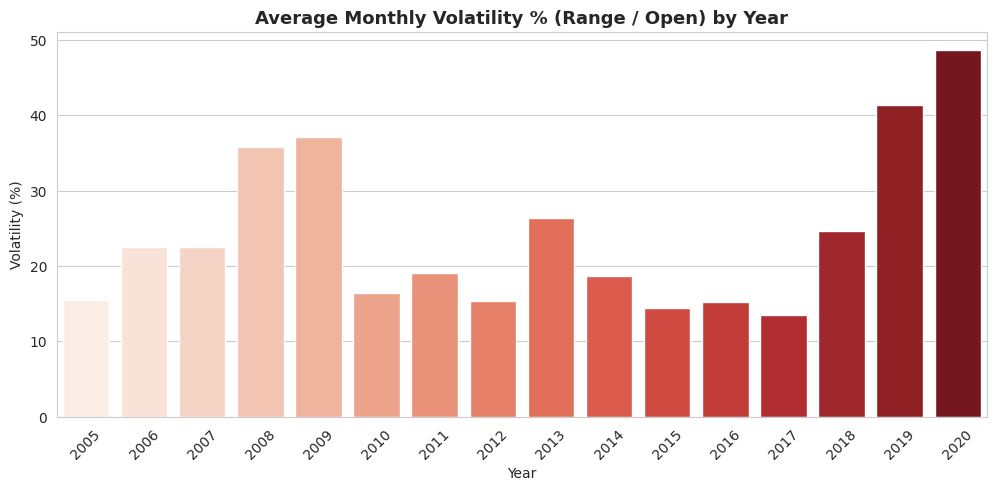

In [ ]:
# Chart - 14 visualization code
vol = data.groupby('Year')['Volatility_%'].mean().reset_index()
plt.figure(figsize=(12, 5))
sns.barplot(data=vol, x='Year', y='Volatility_%', palette='Reds')
plt.title('Average Monthly Volatility % (Range / Open) by Year')
plt.ylabel('Volatility (%)'); plt.xticks(rotation=45)
plt.show()

##### 1. Why did you pick the specific chart?
Using range as a percentage of the Open price removes the effect of price level, so risk can be compared fairly across years.

##### 2. What is/are the insight(s) found from the chart?
Relative volatility was high in 2006-2009 (small base price and the global financial crisis, peaking near 37%), became lower and steadier in 2010-2017, and rose again sharply in 2018-2020 (about 41% in 2019 and about 49% in 2020).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: the stable years 2010-2017 are when the stock rewarded investors with limited relative risk. Negative: the sudden rise in 2019-2020 is an early warning signal that risk monitoring could have used before the crash was complete.

#### Chart - 15 : Up vs Down Months by Year (Bivariate: Categorical vs Categorical)

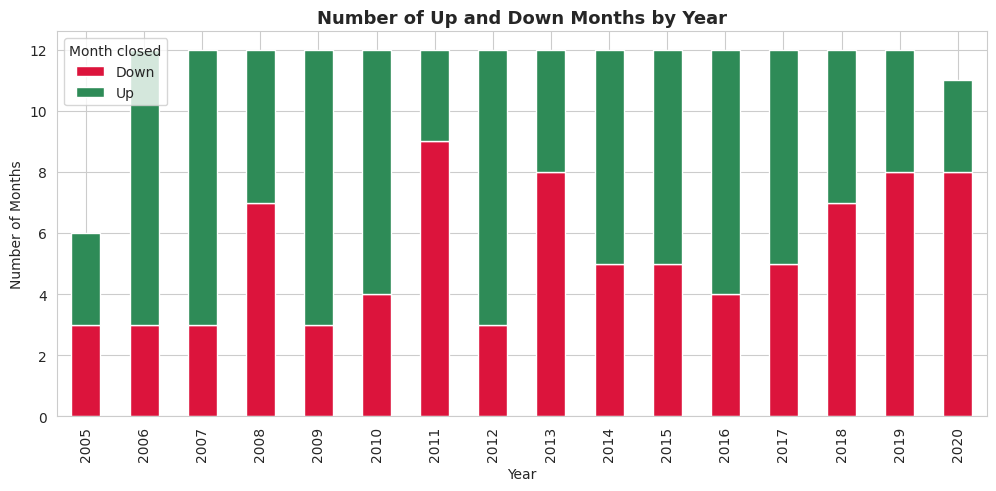

In [ ]:
# Chart - 15 visualization code
ct = pd.crosstab(data['Year'], data['Direction'])
ct.plot(kind='bar', stacked=True, figsize=(12, 5), color={'Up': 'seagreen', 'Down': 'crimson'})
plt.title('Number of Up and Down Months by Year')
plt.ylabel('Number of Months'); plt.xlabel('Year')
plt.legend(title='Month closed')
plt.show()

##### 1. Why did you pick the specific chart?
A stacked bar chart compares two categorical variables (Year and Up/Down direction), showing how the count of winning and losing months changed.

##### 2. What is/are the insight(s) found from the chart?
Up-months dominate in several growth years (for example 2006, 2007, 2009, 2016 and 2017), while 2018, 2019 and 2020 have more down-months than up-months (8 of 12 in both 2019 and 2020).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: consistent up-months in the growth era supported steady wealth creation. Negative: when down-months dominate (2019-2020), the loss builds quickly; a rising share of down-months can be used as a trend-reversal warning.

#### Chart - 16 : Year x Month Heatmap of Close Price (Multivariate)

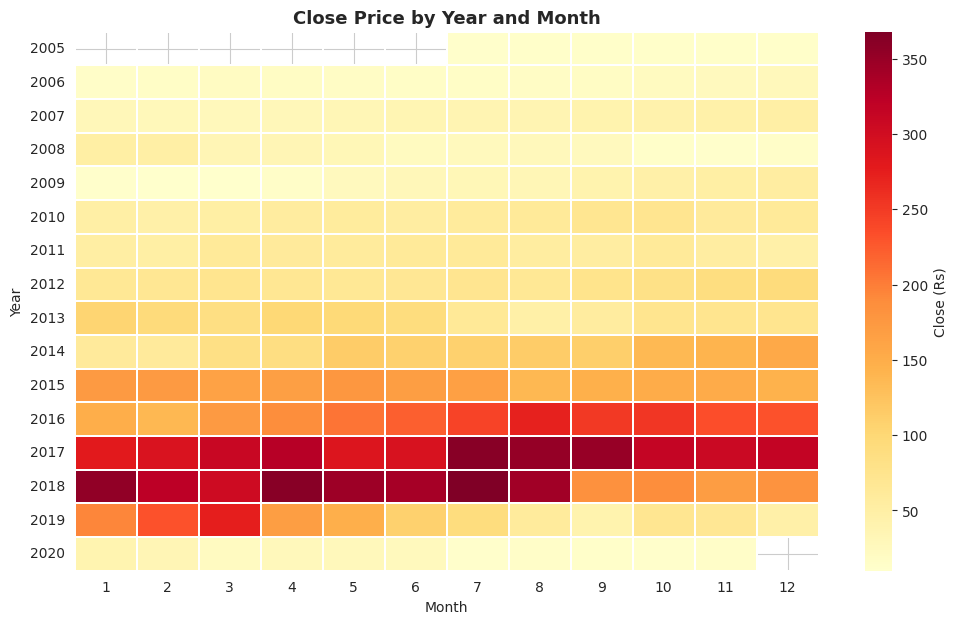

In [ ]:
# Chart - 16 visualization code
pivot = data.pivot_table(index='Year', columns='Month', values='Close')
plt.figure(figsize=(12, 7))
sns.heatmap(pivot, cmap='YlOrRd', annot=False, linewidths=0.3, cbar_kws={'label': 'Close (Rs)'})
plt.title('Close Price by Year and Month')
plt.show()

##### 1. Why did you pick the specific chart?
A heatmap of Year x Month shows price level for two categorical dimensions at once, so both trend and seasonality are visible.

##### 2. What is/are the insight(s) found from the chart?
Colour intensity rises along the years until 2017-2018 and then fades; colours are almost uniform within each row (year), which means the year matters much more than the month.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: confirms that the long-term trend dominates and seasonality is minor, so investors should focus on fundamentals. Negative: the fading colours after 2018 summarise the crash and the missing data in 2005 (starts in July) is normal, not an error.

#### Chart - 17 : Close Price vs 12-Month Rolling Average (Time Series)

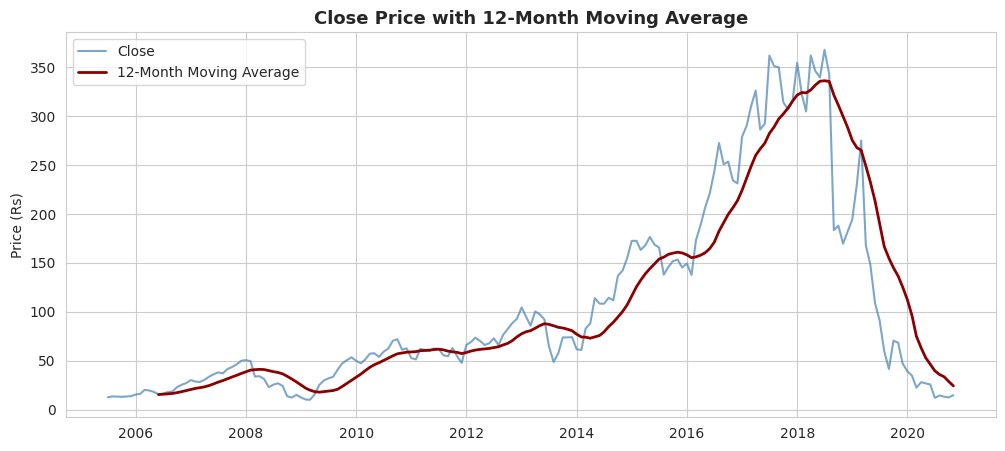

In [ ]:
# Chart - 17 visualization code
plt.figure(figsize=(12, 5))
plt.plot(data['Date'], data['Close'], label='Close', color='steelblue', alpha=0.7)
plt.plot(data['Date'], data['Rolling_12M'], label='12-Month Moving Average', color='darkred', linewidth=2)
plt.title('Close Price with 12-Month Moving Average')
plt.ylabel('Price (Rs)'); plt.legend()
plt.show()

##### 1. Why did you pick the specific chart?
A moving average smooths short-term noise and is widely used to see trend direction and crossovers.

##### 2. What is/are the insight(s) found from the chart?
Close stayed above the moving average for most of the growth period, and crossed below it around late 2018 and stayed below it through 2019-2020, confirming the trend reversal.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: a moving-average crossover is a simple and effective rule to exit before deeper losses. Negative: during the 2020 collapse even this rule reacted late, because the fall was very fast.

#### Chart - 18 : Drawdown from Previous Peak (Time Series)

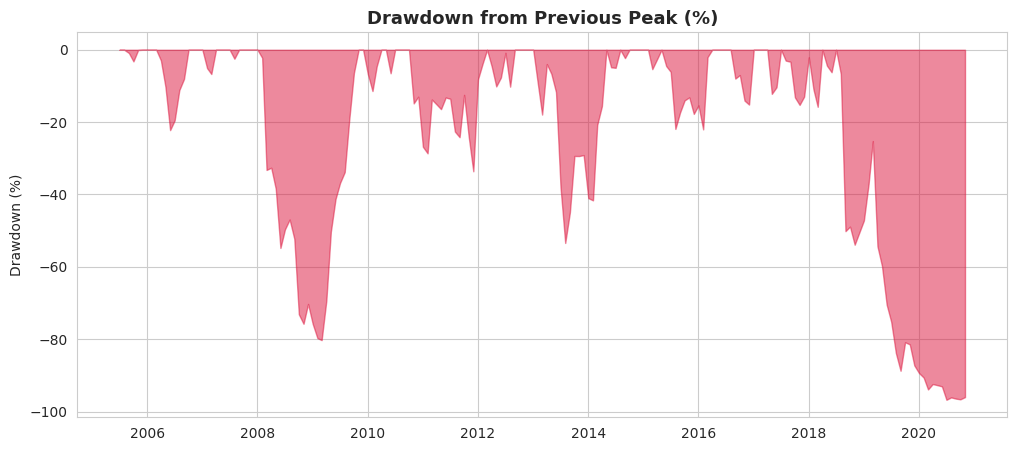

Maximum drawdown: -96.8%


In [ ]:
# Chart - 18 visualization code
plt.figure(figsize=(12, 5))
plt.fill_between(data['Date'], data['Drawdown_%'], 0, color='crimson', alpha=0.5)
plt.title('Drawdown from Previous Peak (%)')
plt.ylabel('Drawdown (%)')
plt.show()
print(f"Maximum drawdown: {data['Drawdown_%'].min():.1f}%")

##### 1. Why did you pick the specific chart?
A drawdown chart shows how deep and how long the stock stayed below its previous high, which is the most direct measure of investor pain.

##### 2. What is/are the insight(s) found from the chart?
There were moderate drawdowns in 2008-2009 and 2011, but the 2018-2020 drawdown is by far the deepest, with a maximum of about 97% from the peak. The stock did not make a new high after 2018.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: understanding past drawdowns helps in designing risk limits. Negative: a drawdown of about 97% means a loss that needs a gain of more than 25 times to recover, a clear case of negative growth driven by governance and asset-quality failure.

#### Chart - 19 : Correlation Heatmap (Multivariate)

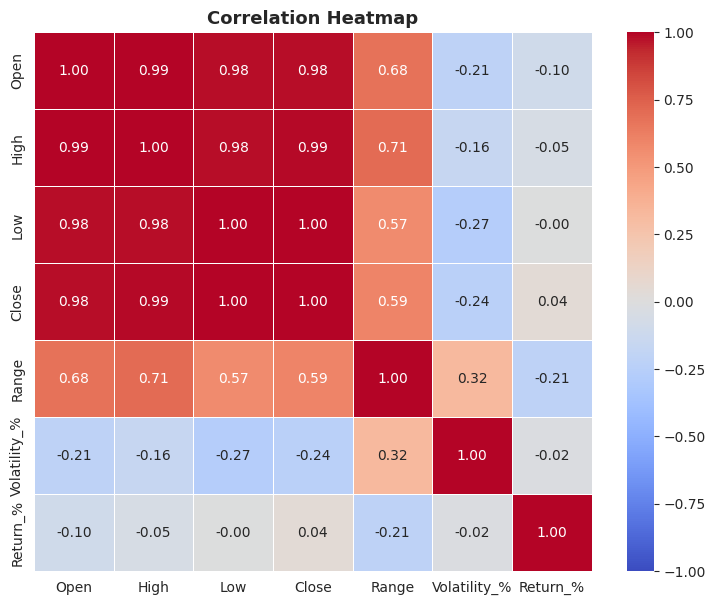

In [ ]:
# Chart - 19 Correlation Heatmap visualization code
num_cols = ['Open', 'High', 'Low', 'Close', 'Range', 'Volatility_%', 'Return_%']
plt.figure(figsize=(9, 7))
sns.heatmap(data[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

##### 1. Why did you pick the specific chart?
A correlation heatmap summarises the linear relationship between all numeric variables in one chart and is key for feature selection.

##### 2. What is/are the insight(s) found from the chart?
Open, High, Low and Close are almost perfectly correlated (0.98 to 0.99). Range is strongly correlated with price level, while Return % and Volatility % have a weak relationship with the price variables.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: strong correlation shows data consistency and helps predictive models. Negative: multicollinearity among Open/High/Low/Close means that using all of them in a regression model would be redundant and unstable, so only one or two should be kept.

#### Chart - 20 : Pair Plot (Multivariate)

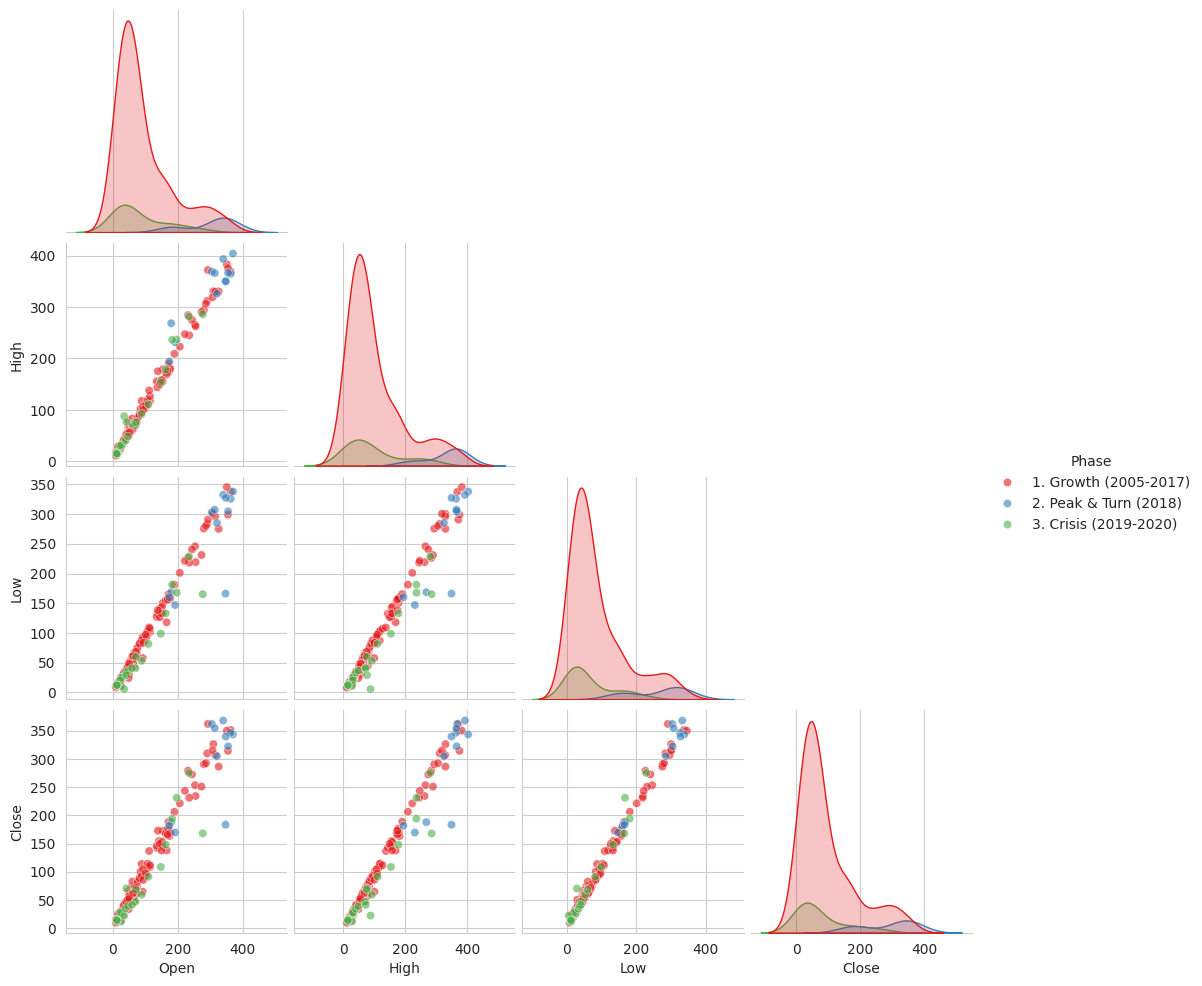

In [ ]:
# Chart - 20 Pair Plot visualization code
sns.pairplot(data[['Open', 'High', 'Low', 'Close', 'Phase']].sort_values('Phase'), hue='Phase', palette='Set1', corner=True, plot_kws={'alpha': 0.6})
plt.show()

##### 1. Why did you pick the specific chart?
A pair plot shows every pairwise relationship and every distribution in one view, with colour showing the market phase.

##### 2. What is/are the insight(s) found from the chart?
All price pairs show tight linear patterns. The 2018 phase sits in the upper right of every plot, the crisis phase clusters at the lower left, and the diagonal histograms are right-skewed.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: the clear clusters by phase support regime-based modelling. Negative: since distributions are skewed and the 2018 phase is an outlier region, a simple linear model trained on the whole period would perform poorly in a crisis.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
1. **Track risk, not only price:** monitor monthly range %, drawdown and the 12-month moving average. A close below the moving average together with rising volatility should trigger a review or exit.
2. **Give governance and asset-quality news the highest weight:** the 2018 peak and the following fall show that corporate governance, leadership change and bad-loan news affected the price far more than seasonality.
3. **Use staged entries and stop-losses:** because the monthly return standard deviation is about 16.5% and the worst month was about -53%, investors should use position limits, staggered buying and stop-loss levels instead of one large purchase.
4. **Do not rely on seasonality:** the Year x Month heatmap and the calendar-month return chart show that month effects are weak compared with the trend.
5. **Prepare the data for forecasting:** use log-transformed Close, keep only one of Open/High/Low/Close as a feature (to avoid multicollinearity), add Phase or a crisis flag as a structural-break variable, and try ARIMA/SARIMA or LSTM models.
6. **Be cautious about recovery:** the stock was still more than 90% below its peak in late 2020, so any recovery should be confirmed by the price staying above its 12-month average and by lower volatility before increasing exposure.

# **Conclusion**

Yes Bank's stock went through three clear phases: a long and steady growth period (2005-2017), a peak in July 2018 at Rs 367.90, and a deep crisis (2019-2020) with a maximum drawdown above 90%. The price variables are almost perfectly correlated, the Close price is right-skewed, and monthly returns are very volatile (about 16.5% standard deviation). Seasonality is weak compared with the long-term trend and the 2018 shock. The 20 charts show that risk indicators such as range %, drawdown and the moving average give earlier warnings than price level alone. The main business lesson is that growth without strong governance and asset quality is not sustainable, and the best response for investors is disciplined risk management. The cleaned and feature-engineered data is ready for time-series forecasting in the next stage.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***